In [2]:
# dependencies

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df1 = pd.read_csv('wine_data.csv')

In [4]:
df1

,1,14.23,1.71,2.43,15.6,127,2.8,3.06,.28,2.29,5.64,1.04,3.92,1065
0,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
1,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
2,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
3,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
4,1,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
173,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
174,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
175,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [5]:
# now lets take selective col , and name them cause we dont have naming here

df1 = pd.read_csv('wine_data.csv', header=None, usecols=[0,1,2])
df1.columns= ['class label', 'alcohol', 'malic acid']

    header=None: 
    This argument tells the function that the CSV file does not have a header row. By default, pandas assumes the first row contains column names, but by setting 
    
    header=None, 
    you're instructing it to treat the first row as data and assign default integer column names (0, 1, 2, and so on).

    usecols=[0,1,2]: 
    This is a crucial argument that specifies which columns to read from the CSV file. Instead of reading all columns, it only reads the columns at index 0, 1, and 2 (the first, second, and third columns) into the DataFrame. This is useful for saving memory or when you only need a subset of the data.
    
    
    df1.columns: This accesses the existing column names of the DataFrame 

    df1 = ['class label', 'alcohol', 'malic acid']: 
    This assigns a new list of string names to the columns. Since we used usecols=[0,1,2], the DataFrame currently has default column names 0, 1, 2. This line renames them to more descriptive and meaningful names:

Column 0 becomes 'class label'

Column 1 becomes 'alcohol'

Column 2 becomes 'malic acid'

In [6]:
df1

,class label,alcohol,malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


In [7]:
# now lets see the data

<Axes: xlabel='alcohol', ylabel='Density'>

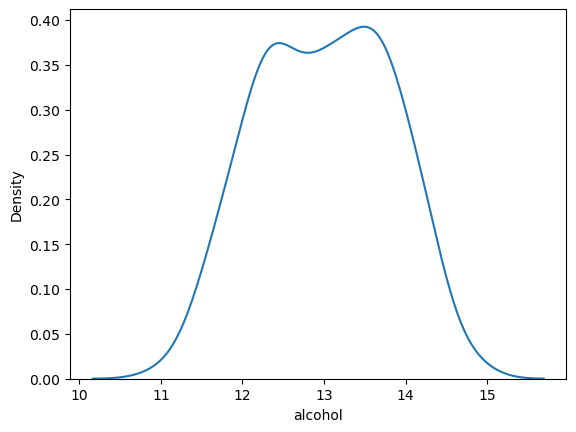

In [9]:
sns.kdeplot(df1['alcohol'])

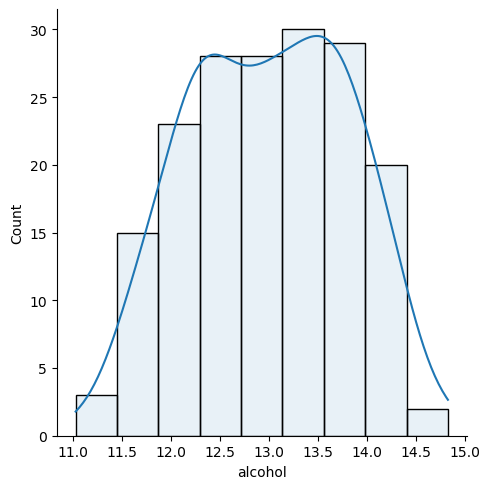

In [15]:
sns.displot(df1['alcohol'], kde=True, alpha=0.1)

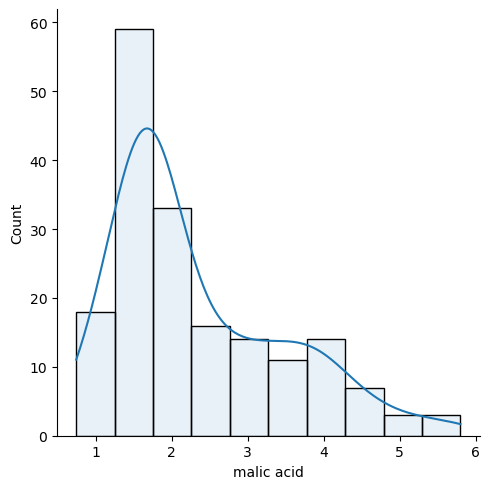

In [14]:
sns.displot(df1['malic acid'], kde=True, alpha=0.1)

<Axes: xlabel='alcohol', ylabel='malic acid'>

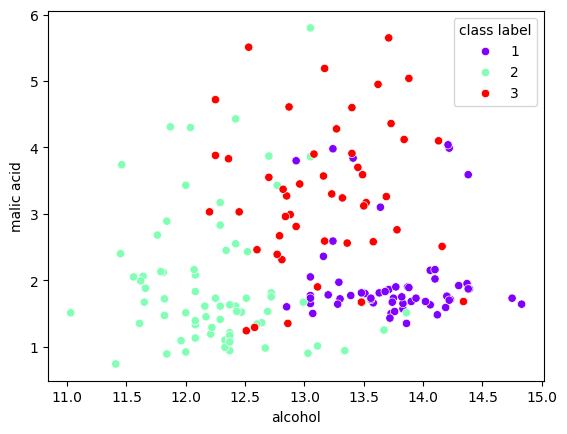

In [20]:
sns.scatterplot(data=df1, x='alcohol', y='malic acid', hue='class label', palette='rainbow')

<Axes: xlabel='alcohol', ylabel='malic acid'>

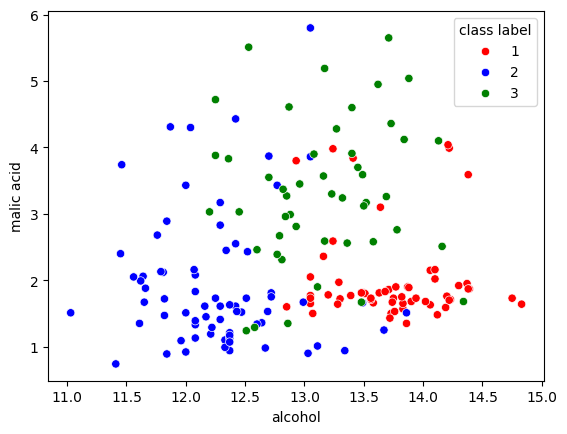

In [22]:
# we can also give our own pallet

color=['red','blue','green']

sns.scatterplot(data=df1, x='alcohol', y='malic acid', hue='class label', palette= color)

In [24]:
# lets start normalization - min_max

from sklearn.model_selection import train_test_split

x_train, x_test, y_train , y_test = train_test_split(df1.drop('class label', axis=1),
                                                    df1['class label'],
                                                    test_size=0.2,
                                                    random_state=0)



In [26]:
x_train.shape, x_test.shape

((142, 2), (36, 2))

In [27]:
# this shows , we have 142 rows of 2 columns for train and 36 rows with 2 col for test , 
# SUCESSFUL

In [31]:
x_train. head() 

,alcohol,malic acid
161,13.69,3.26
92,12.69,1.53
94,11.62,1.99
174,13.40,3.91
24,13.50,1.81


In [32]:
x_test.head()

,alcohol,malic acid
54,13.74,1.67
151,12.79,2.67
63,12.37,1.13
55,13.56,1.73
123,13.05,5.80


In [33]:
# normalization / Scaling

from sklearn.preprocessing import MinMaxScaler

#  lets make object of this class

scaler = MinMaxScaler()

# train / fit this scaler on train data

scaler.fit(x_train)

# now transfrom both train and test 

x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [34]:
x_test_scaled

array([[0.72849462, 0.18940937],
       [0.47311828, 0.39307536],
       [0.36021505, 0.07942974],
       [0.68010753, 0.20162933],
       [0.54301075, 1.0305499 ],
       [0.14247312, 0.26680244],
       [0.81451613, 0.28716904],
       [0.35752688, 0.6293279 ],
       [0.32795699, 0.20162933],
       [0.28225806, 0.22199593],
       [0.62634409, 0.3706721 ],
       [0.76612903, 0.87576375],
       [0.85215054, 0.20773931],
       [0.36021505, 0.06720978],
       [0.68548387, 0.37474542],
       [0.26075269, 0.03665988],
       [0.73387097, 0.16089613],
       [0.84946237, 0.17311609],
       [0.4327957 , 0.12627291],
       [0.75268817, 0.18533605],
       [0.55913978, 0.05498982],
       [0.54301075, 0.18533605],
       [0.59408602, 0.37678208],
       [0.39784946, 0.20162933],
       [0.34946237, 0.07331976],
       [0.40053763, 0.34419552],
       [0.37634409, 0.16089613],
       [0.30376344, 0.17718941],
       [0.19623656, 0.39511202],
       [0.73924731, 0.4114053 ],
       [0.

In [35]:
# now lets make these series back to dataframe

x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns)

In [37]:
x_test_scaled.head(2)

,alcohol,malic acid
0,0.728495,0.189409
1,0.473118,0.393075


In [39]:
# basic stat of data

np.round(x_train.describe(), 2)

,alcohol,malic acid
count,142.00,142.00
mean,12.98,2.37
std,0.81,1.12
min,11.03,0.74
25%,12.35,1.60
50%,13.04,1.90
75%,13.64,3.22
max,14.75,5.65


In [40]:
np.round(x_train_scaled.describe(), 2)

,alcohol,malic acid
count,142.00,142.00
mean,0.53,0.33
std,0.22,0.23
min,0.00,0.00
25%,0.35,0.18
50%,0.54,0.24
75%,0.70,0.51
max,1.00,1.00


In [42]:
# now we can see that both the min and max values of malic acid and alcohol have become 0 ,1 after 
# min max normalization

# mean and standard deviation behaviour is not giverned here 

In [43]:
# now lets visualize this transfromations 

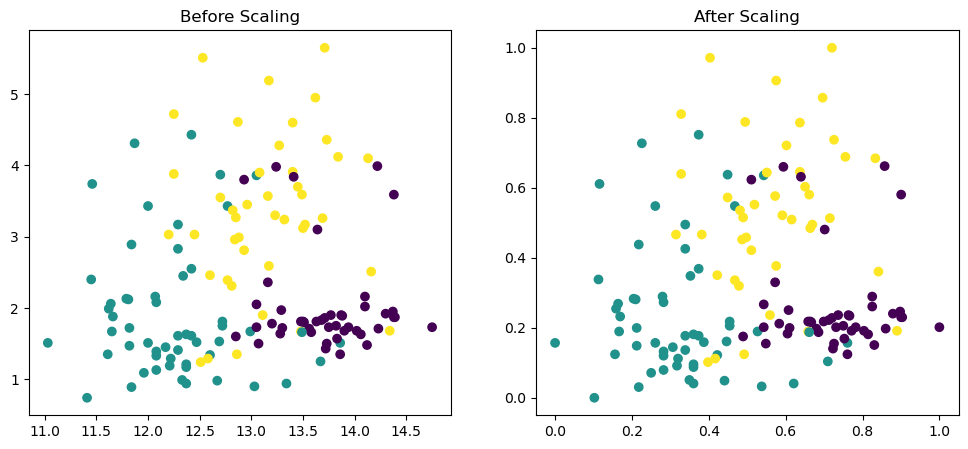

In [45]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(x_train['alcohol'], x_train['malic acid'],c=y_train)
ax1.set_title("Before Scaling")
ax2.scatter(x_train_scaled['alcohol'], x_train_scaled['malic acid'],c=y_train)
ax2.set_title("After Scaling")
plt.show()

In [46]:
# here there is no change is shape of data , 
# in some cases when data is not normally distributed then data shape may change

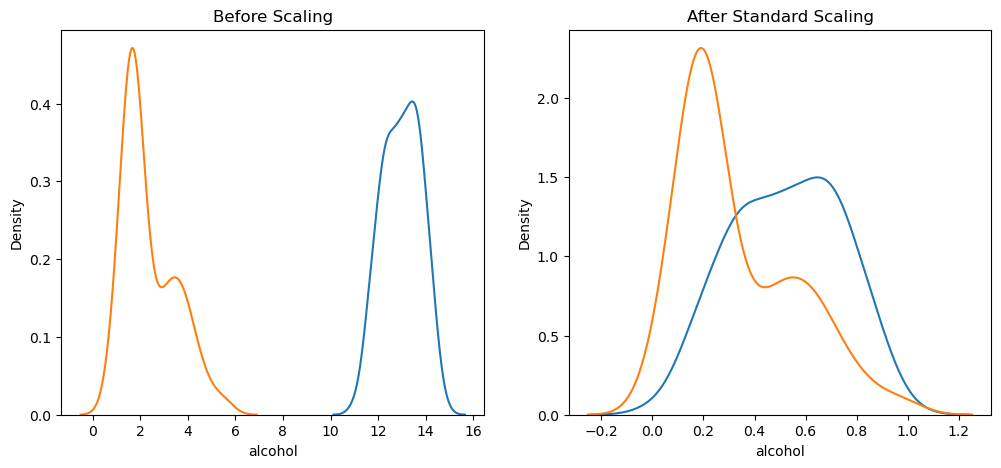

In [47]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(x_train['alcohol'], ax=ax1)
sns.kdeplot(x_train['malic acid'], ax=ax1)

# after scaling
ax2.set_title('After Standard Scaling')
sns.kdeplot(x_train_scaled['alcohol'], ax=ax2)
sns.kdeplot(x_train_scaled['malic acid'], ax=ax2)
plt.show()

In [48]:
# as we can see that before the malic acid and alcohol were of different range , but after transfrom 
# there range of values have become same so i.e. easy to compare

In [49]:
# now lets see the shape of individual data col 



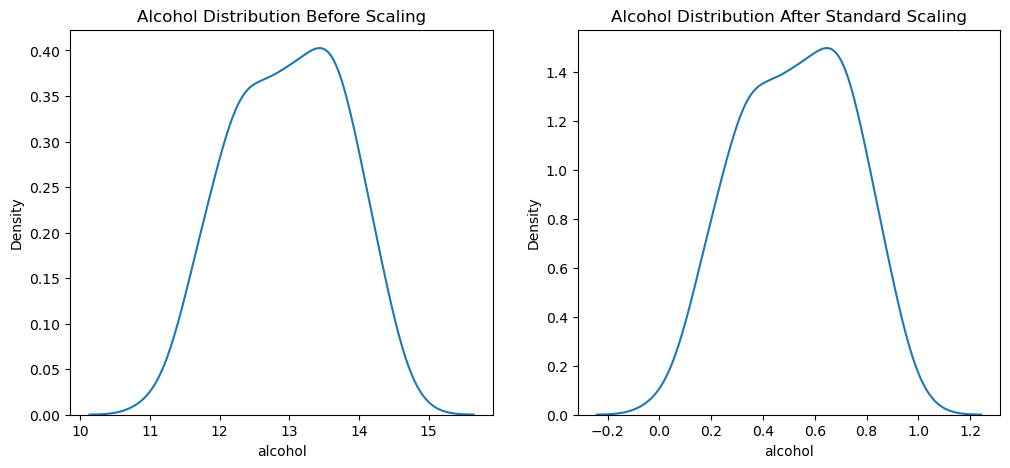

In [50]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Alcohol Distribution Before Scaling')
sns.kdeplot(x_train['alcohol'], ax=ax1)

# after scaling
ax2.set_title('Alcohol Distribution After Standard Scaling')
sns.kdeplot(x_train_scaled['alcohol'], ax=ax2)
plt.show()

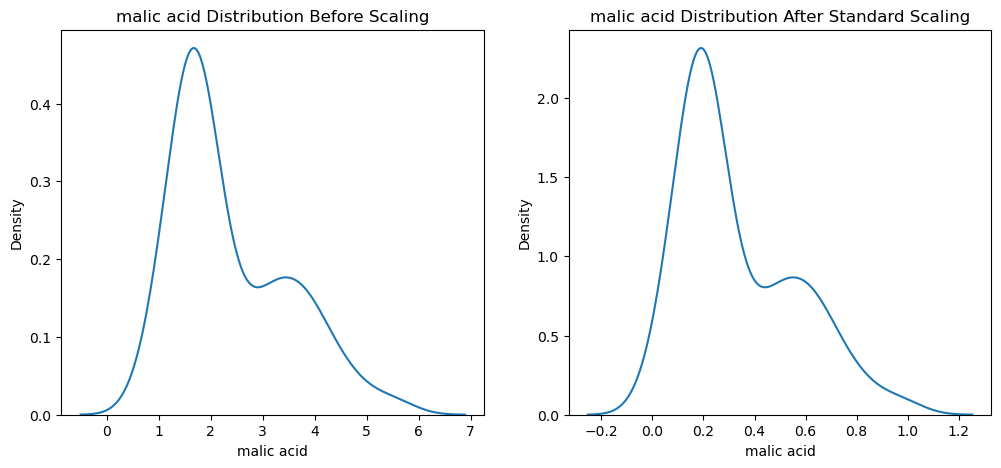

In [51]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('malic acid Distribution Before Scaling')
sns.kdeplot(x_train['malic acid'], ax=ax1)

# after scaling
ax2.set_title('malic acid Distribution After Standard Scaling')
sns.kdeplot(x_train_scaled['malic acid'], ax=ax2)
plt.show()

In [52]:
# there is difference appart from the scale , but that's not necessary , sometimes it may change